In [1]:
# CELDA 1: SETUP Y CONFIGURACIÓN DE ENTORNO
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. REPRODUCIBILIDAD ABSOLUTA (Regla QA #4)
np.random.seed(42)

# 2. CONFIGURACIÓN DE GRÁFICOS APA 7 (Regla QA #3)
sns.set_theme(style="whitegrid", context="notebook", font="sans-serif")
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

# 3. RUTAS DEL PROYECTO
PROJECT_ROOT = Path.cwd().parent  # Sube desde notebooks/ a Tulcan_DesLocal_2027_2030/
OUTPUT_FIG = PROJECT_ROOT / "outputs" / "figuras"
OUTPUT_TAB = PROJECT_ROOT / "outputs" / "tablas"

# Crear carpetas si no existen
OUTPUT_FIG.mkdir(parents=True, exist_ok=True)
OUTPUT_TAB.mkdir(parents=True, exist_ok=True)

# 4. DATOS BASE DE TULCÁN (Regla QA #1: Línea base ficticia del caso)
BASE_TULCAN = {
    "poblacion_total": 85000,
    "pobreza_pct": 0.32,
    "desempleo_juvenil_pct": 0.23,
    "informalidad_pct": 0.58,
    "poblacion_rural_pct": 0.45,
    "alcantarillado_pct": 0.62,
    "presupuesto_total_usd": 2000000,
    "estructura_productiva_pct": {
        "Agrícola": 40,
        "Comercial": 35,
        "Industrial": 10,
        "Turismo_y_otros": 15
    }
}

print("✅ Entorno configurado. Semilla fijada en 42.")
print(f"📁 Rutas de salida: {OUTPUT_FIG}")
print(f"📊 Datos base de Tulcán cargados (85.000 hab., $2.000.000 USD)")

✅ Entorno configurado. Semilla fijada en 42.
📁 Rutas de salida: c:\Users\Oficina\Documents\Análisis de Datos Salomón\Tulcan_DesLocal_2027_2030\outputs\figuras
📊 Datos base de Tulcán cargados (85.000 hab., $2.000.000 USD)


In [2]:
# ==============================================================================
# CELDA 2: MÓDULO 1.1 - Diagnóstico de brechas y concentración sectorial (Actividad 1)
# ==============================================================================

# 1. CÁLCULO DE POBLACIÓN ABSOLUTA EN BRECHA
pob_total = BASE_TULCAN["poblacion_total"]

brechas = {
    "Pobreza (absoluta)": int(pob_total * BASE_TULCAN["pobreza_pct"]),
    "Población Rural (absoluta)": int(pob_total * BASE_TULCAN["poblacion_rural_pct"]),
    "Déficit de Alcantarillado (absoluto)": int(pob_total * (1 - BASE_TULCAN["alcantarillado_pct"]))
}

print("📊 1. DIAGNÓSTICO DE BRECHAS POBLACIONALES (Tulcán)")
print("-" * 60)
for concepto, valor in brechas.items():
    print(f"  • {concepto:<38} : {valor:>7,} habitantes")

# 2. CÁLCULO DEL ÍNDICE DE HERFINDAHL-HIRSCHMAN (IHH)
# Se usa la estructura productiva en porcentajes enteros (40, 35, 10, 15)
# Fórmula: IHH = Σ (participación_i)^2
estructura = list(BASE_TULCAN["estructura_productiva_pct"].values())
sectores = list(BASE_TULCAN["estructura_productiva_pct"].keys())

ihh = sum([x**2 for x in estructura])

print("\n📈 2. CONCENTRACIÓN SECTORIAL (Índice de Herfindahl-Hirschman)")
print("-" * 60)
print(f"  • Estructura productiva (%): {estructura}")
print(f"  • IHH calculado: {ihh}")
print(f"  • Interpretación: {'Alta concentración' if ihh > 2500 else 'Moderada/Baja concentración'} (Umbral alta: > 2,500)")

# 3. VALIDACIÓN MATEMÁTICA (QA ASSERTS) - Regla QA #4
# Estos asserts detendrán el código con un error si hay el más mínimo desvío.
assert sum(estructura) == 100, "❌ Error QA: La estructura productiva no suma 100%"
assert ihh == 3150, f"❌ Error QA: El IHH debería ser 3150, pero se calculó {ihh}"
assert brechas["Pobreza (absoluta)"] == 27200, "❌ Error QA: Cálculo de pobreza absoluta incorrecto"
assert brechas["Déficit de Alcantarillado (absoluto)"] == 32300, "❌ Error QA: Cálculo de déficit de alcantarillado incorrecto"

print("\n✅ VALIDACIÓN QA: Todos los cálculos matemáticos son consistentes y cuadran perfectamente.")

📊 1. DIAGNÓSTICO DE BRECHAS POBLACIONALES (Tulcán)
------------------------------------------------------------
  • Pobreza (absoluta)                     :  27,200 habitantes
  • Población Rural (absoluta)             :  38,250 habitantes
  • Déficit de Alcantarillado (absoluto)   :  32,300 habitantes

📈 2. CONCENTRACIÓN SECTORIAL (Índice de Herfindahl-Hirschman)
------------------------------------------------------------
  • Estructura productiva (%): [40, 35, 10, 15]
  • IHH calculado: 3150
  • Interpretación: Alta concentración (Umbral alta: > 2,500)

✅ VALIDACIÓN QA: Todos los cálculos matemáticos son consistentes y cuadran perfectamente.


In [3]:
# ==============================================================================
# CELDA 3: MÓDULO 1.2 - Asignación presupuestaria multicriterio y sensibilidad (Actividad 4)
# ==============================================================================

# -----------------------------------------------------------------------------
# 3.1. RESTRICCIÓN PER CÁPITA (justificación de capital catalizador)
# -----------------------------------------------------------------------------
presupuesto = BASE_TULCAN["presupuesto_total_usd"]
poblacion = BASE_TULCAN["poblacion_total"]
periodos = 4  # cuatrienio 2027-2030

inv_per_capita_total = presupuesto / poblacion
inv_per_capita_anual = inv_per_capita_total / periodos

print("💰 3.1. RESTRICCIÓN PER CÁPITA (Capital catalizador/apalancador)")
print("-" * 65)
print(f"  • Presupuesto total cuatrienal       : ${presupuesto:>12,.2f}")
print(f"  • Inversión per cápita (4 años)      : ${inv_per_capita_total:>10.2f}")
print(f"  • Inversión per cápita anual         : ${inv_per_capita_anual:>10.2f}")
print(f"  • Interpretación: monto catalizador que debe apalancar")
print(f"    recursos privados, cooperación y transferencia nacional.")

# -----------------------------------------------------------------------------
# 3.2. MATRIZ DE PRIORIZACIÓN MULTICRITERIO (6 ejes × 4 criterios)
# Puntuaciones base (1-10) justificadas para el contexto de Tulcán
# -----------------------------------------------------------------------------
ejes = [
    "1. Infraestructura productiva",
    "2. Emprendimiento y empleo",
    "3. Turismo y promoción territorial",
    "4. Gestión ambiental",
    "5. Capacitación e innovación",
    "6. Fortalecimiento institucional"
]

# Filas = ejes, Columnas = criterios:
# [Empleo/Pobreza, Cierre brecha productiva, Apalancamiento, Sostenibilidad ambiental]
matriz_base = np.array([
    [7, 8, 7, 5],   # Eje 1: Infraestructura
    [9, 6, 7, 6],   # Eje 2: Emprendimiento (alto impacto social)
    [7, 5, 9, 8],   # Eje 3: Turismo (alto apalancamiento y ambiental)
    [5, 4, 6, 10],  # Eje 4: Ambiental (máxima sostenibilidad)
    [7, 7, 8, 7],   # Eje 5: Capacitación (largo plazo)
    [6, 5, 7, 6]    # Eje 6: Institucional (transversal)
], dtype=float)

criterios = ["Empleo/Pobreza", "Brecha productiva", "Apalancamiento", "Sostenibilidad"]

# Pesos base (suman 1)
pesos_base = np.array([0.35, 0.30, 0.20, 0.15])

# Puntuación ponderada por eje
puntaje_ponderado = matriz_base @ pesos_base

# Asignación proporcional del presupuesto
proporcion = puntaje_ponderado / puntaje_ponderado.sum()
asignacion_usd = proporcion * presupuesto

# Tabla resumen
df_asignacion = pd.DataFrame({
    "Eje estratégico": ejes,
    "Puntaje ponderado": np.round(puntaje_ponderado, 3),
    "Proporción (%)": np.round(proporcion * 100, 2),
    "Asignación (USD)": np.round(asignacion_usd, 2)
})

print("\n📊 3.2. ASIGNACIÓN PRESUPUESTARIA MULTICRITERIO (Pesos base)")
print("-" * 65)
print(df_asignacion.to_string(index=False))

# -----------------------------------------------------------------------------
# 3.3. VALIDACIÓN MATEMÁTICA (QA ASSERTS)
# -----------------------------------------------------------------------------
assert np.isclose(asignacion_usd.sum(), presupuesto, atol=0.01), \
    f"❌ Error QA: La asignación suma ${asignacion_usd.sum():.2f}, no ${presupuesto}"
assert np.isclose(proporcion.sum(), 1.0, atol=1e-6), \
    f"❌ Error QA: Las proporciones suman {proporcion.sum()}, no 1.0"
assert len(ejes) == 6, "❌ Error QA: Deben ser exactamente 6 ejes"
assert np.isclose(pesos_base.sum(), 1.0), "❌ Error QA: Los pesos no suman 1"

print("\n✅ VALIDACIÓN QA: Asignación suma exactamente $2.000.000 y 100%")

# -----------------------------------------------------------------------------
# 3.4. ANÁLISIS DE SENSIBILIDAD (Perturbación ±10% de los pesos)
# -----------------------------------------------------------------------------
print("\n🔬 3.3. ANÁLISIS DE SENSIBILIDAD (Robustez del ranking)")
print("-" * 65)

# Generamos 1.000 perturbaciones aleatorias de los pesos (±10%)
N_SENS = 1000
np.random.seed(42)  # reproducibilidad
ranking_base = np.argsort(-puntaje_ponderado)  # ranking base (descendente)

rankings_perturbados = []
for _ in range(N_SENS):
    # Perturbación uniforme ±10%
    perturbacion = np.random.uniform(-0.10, 0.10, size=4)
    pesos_perturbados = pesos_base * (1 + perturbacion)
    # Normalizar a 1
    pesos_perturbados = pesos_perturbados / pesos_perturbados.sum()
    # Recalcular puntajes
    puntajes_p = matriz_base @ pesos_perturbados
    rankings_perturbados.append(np.argsort(-puntajes_p))

rankings_perturbados = np.array(rankings_perturbados)

# Calcular correlaciones de rangos (Spearman ρ y Kendall τ) entre base y cada perturbación
spearman_vals = []
kendall_vals = []
for r in rankings_perturbados:
    rho, _ = stats.spearmanr(ranking_base, r)
    tau, _ = stats.kendalltau(ranking_base, r)
    spearman_vals.append(rho)
    kendall_vals.append(tau)

spearman_vals = np.array(spearman_vals)
kendall_vals = np.array(kendall_vals)

print(f"  • Iteraciones de sensibilidad      : {N_SENS}")
print(f"  • Perturbación aplicada            : ±10% sobre cada peso (normalizado)")
print(f"  • Spearman ρ  (media ± desv)       : {spearman_vals.mean():.4f} ± {spearman_vals.std():.4f}")
print(f"  • Kendall  τ  (media ± desv)       : {kendall_vals.mean():.4f} ± {kendall_vals.std():.4f}")
print(f"  • % de iteraciones con ranking     : {(spearman_vals > 0.95).mean()*100:.1f}%")
print(f"    idéntico al base (ρ > 0.95)")

# Interpretación de robustez
if spearman_vals.mean() > 0.95:
    robustez = "ALTA — el ranking es muy estable ante cambios en los pesos"
elif spearman_vals.mean() > 0.85:
    robustez = "MODERADA-ALTA — el ranking es razonablemente estable"
else:
    robustez = "MODERADA — revisar criterios o pesos"

print(f"\n  📌 Conclusión de robustez: {robustez}")

# Guardar tabla en CSV para el informe
df_asignacion.to_csv(OUTPUT_TAB / "asignacion_presupuestaria.csv", index=False, sep=";", decimal=",")
print(f"\n💾 Tabla exportada a: {OUTPUT_TAB / 'asignacion_presupuestaria.csv'}")

💰 3.1. RESTRICCIÓN PER CÁPITA (Capital catalizador/apalancador)
-----------------------------------------------------------------
  • Presupuesto total cuatrienal       : $2,000,000.00
  • Inversión per cápita (4 años)      : $     23.53
  • Inversión per cápita anual         : $      5.88
  • Interpretación: monto catalizador que debe apalancar
    recursos privados, cooperación y transferencia nacional.

📊 3.2. ASIGNACIÓN PRESUPUESTARIA MULTICRITERIO (Pesos base)
-----------------------------------------------------------------
                   Eje estratégico  Puntaje ponderado  Proporción (%)  Asignación (USD)
     1. Infraestructura productiva               7.00           17.52         350438.05
        2. Emprendimiento y empleo               7.25           18.15         362953.69
3. Turismo y promoción territorial               6.95           17.40         347934.92
              4. Gestión ambiental               5.65           14.14         282853.57
      5. Capacitación e 

In [4]:
# ==============================================================================
# CELDA 4: MÓDULO 1.3 - Validación estocástica de metas 2027-2030 (Actividad 5)
# ==============================================================================

# 1. CONFIGURACIÓN DE LA SIMULACIÓN DE MONTE CARLO
N_ITER = 10000
np.random.seed(42)  # Reproducibilidad absoluta (Regla QA #4)

# 2. DEFINICIÓN DE METAS Y DISTRIBUCIONES TRIANGULARES PARA 2030
# Formato: (Nombre, Valor Base, Meta Ideal, [min, moda, max] para dist. triangular)
# Nota: Para alcantarillado e industrial, "cumplir meta" es >= al umbral.
# Para pobreza, desempleo e informalidad, "cumplir meta" es <= al umbral.
indicadores = {
    "Pobreza (%)": {
        "base": 32, "meta": 28, "dist": (24, 26, 29), "direccion": "menor"
    },
    "Desempleo juvenil (%)": {
        "base": 23, "meta": 20, "dist": (16, 18, 21), "direccion": "menor"
    },
    "Informalidad laboral (%)": {
        "base": 58, "meta": 52, "dist": (48, 50, 54), "direccion": "menor"
    },
    "Cobertura alcantarillado (%)": {
        "base": 62, "meta": 75, "dist": (70, 75, 79), "direccion": "mayor"
    },
    "Participación Industrial (%)": {
        "base": 10, "meta": 15, "dist": (12, 14, 17), "direccion": "mayor"
    }
}

resultados_sim = {}

print("🎲 4.1. SIMULACIÓN DE MONTE CARLO (N = 10.000 iteraciones)")
print("=" * 75)
print(f"{'Indicador':<25} | {'Media':<6} | {'Mediana':<6} | {'Desv. Est.':<6} | {'IC 95%':<15} | {'Prob. Meta':<8} | {'Asim./Curt.'}")
print("-" * 75)

for nombre, params in indicadores.items():
    # Generar 10,000 muestras de distribución triangular
    muestras = np.random.triangular(left=params["dist"][0], 
                                    mode=params["dist"][1], 
                                    right=params["dist"][2], 
                                    size=N_ITER)
    
    # Métricas estadísticas
    media = np.mean(muestras)
    mediana = np.median(muestras)
    desv = np.std(muestras)
    ic_inf, ic_sup = np.percentile(muestras, [2.5, 97.5])
    asimetria = stats.skew(muestras)
    curtosis = stats.kurtosis(muestras)
    
    # Probabilidad de cumplir la meta
    if params["direccion"] == "menor":
        prob_meta = np.mean(muestras <= params["meta"])
    else:
        prob_meta = np.mean(muestras >= params["meta"])
    
    resultados_sim[nombre] = {
        "Media": media, "Mediana": mediana, "Desv_Est": desv,
        "IC_Inf": ic_inf, "IC_Sup": ic_sup, "Prob_Meta": prob_meta,
        "Asimetria": asimetria, "Curtosis": curtosis, "Muestras": muestras
    }
    
    print(f"{nombre:<25} | {media:>5.1f}% | {mediana:>5.1f}% | {desv:>5.1f}% | "
          f"[{ic_inf:>4.1f}, {ic_sup:>4.1f}] | {prob_meta:>7.1%}  | {asimetria:>5.2f} / {curtosis:>5.2f}")

# 3. CÁLCULO DEL NUEVO IHH 2030 Y CAMBIO ESTRUCTURAL (ΔIHH)
# Asumimos que el crecimiento industrial reduce proporcionalmente a los otros 3 sectores base (40, 35, 15 -> suma 90)
sim_industrial = resultados_sim["Participación Industrial (%)"]["Muestras"]
resto_sectorial = 100 - sim_industrial

# Reescalado proporcional de los sectores restantes
sim_agricola = resto_sectorial * (40 / 90)
sim_comercial = resto_sectorial * (35 / 90)
sim_turismo = resto_sectorial * (15 / 90)

# Cálculo del IHH para cada iteración
ihh_2030_muestras = (sim_agricola**2) + (sim_comercial**2) + (sim_industrial**2) + (sim_turismo**2)

ihh_2030_media = np.mean(ihh_2030_muestras)
ihh_base = 3150
delta_ihh = ihh_2030_media - ihh_base

print("\n📈 4.2. CAMBIO ESTRUCTURAL (Índice de Herfindahl-Hirschman)")
print("-" * 75)
print(f"  • IHH Línea Base (2026)              : {ihh_base}")
print(f"  • IHH Simulado 2030 (Media)          : {ihh_2030_media:.1f}")
print(f"  • IHH Simulado 2030 (Mediana)        : {np.median(ihh_2030_muestras):.1f}")
print(f"  • Cambio Estructural (ΔIHH)          : {delta_ihh:.1f} puntos")
print(f"  • Interpretación: {'Diversificación (menor concentración)' if delta_ihh < 0 else 'Mayor concentración'}")

# 4. VALIDACIÓN MATEMÁTICA (QA ASSERTS)
assert all(0 <= resultados_sim[ind]["Prob_Meta"] <= 1 for ind in indicadores), "❌ Error QA: Probabilidades fuera de [0, 1]"
assert np.isclose(np.mean(sim_agricola + sim_comercial + sim_industrial + sim_turismo), 100, atol=0.1), "❌ Error QA: Sectores no suman 100%"
assert ihh_2030_media < ihh_base, "❌ Error QA: Se esperaba una reducción del IHH (diversificación)"

print("\n✅ VALIDACIÓN QA: Simulación estocástica y cálculos de IHH son matemáticamente consistentes.")

# 5. EXPORTACIÓN DE TABLA RESUMEN A CSV
df_simulacion = pd.DataFrame([
    {
        "Indicador": nombre,
        "Base": params["base"],
        "Meta": params["meta"],
        "Media_2030": round(res["Media"], 2),
        "Mediana_2030": round(res["Mediana"], 2),
        "Desv_Est": round(res["Desv_Est"], 2),
        "IC_Inf_95": round(res["IC_Inf"], 2),
        "IC_Sup_95": round(res["IC_Sup"], 2),
        "Prob_Cumplimiento": round(res["Prob_Meta"], 4),
        "Asimetria": round(res["Asimetria"], 2),
        "Curtosis": round(res["Curtosis"], 2)
    }
    for nombre, params, res in [(n, p, resultados_sim[n]) for n, p in indicadores.items()]
])

df_simulacion.to_csv(OUTPUT_TAB / "simulacion_metas_2030.csv", index=False, sep=";", decimal=",")
print(f"\n💾 Tabla de simulación exportada a: {OUTPUT_TAB / 'simulacion_metas_2030.csv'}")

🎲 4.1. SIMULACIÓN DE MONTE CARLO (N = 10.000 iteraciones)
Indicador                 | Media  | Mediana | Desv. Est. | IC 95%          | Prob. Meta | Asim./Curt.
---------------------------------------------------------------------------
Pobreza (%)               |  26.3% |  26.2% |   1.0% | [24.5, 28.3] |   93.4%  |  0.21 / -0.59
Desempleo juvenil (%)     |  18.3% |  18.3% |   1.0% | [16.5, 20.4] |   93.2%  |  0.18 / -0.60
Informalidad laboral (%)  |  50.7% |  50.5% |   1.2% | [48.6, 53.2] |   83.8%  |  0.31 / -0.57
Cobertura alcantarillado (%) |  74.7% |  74.7% |   1.8% | [71.0, 78.0] |   44.7%  | -0.11 / -0.61
Participación Industrial (%) |  14.3% |  14.2% |   1.0% | [12.5, 16.4] |   26.6%  |  0.21 / -0.61

📈 4.2. CAMBIO ESTRUCTURAL (Índice de Herfindahl-Hirschman)
---------------------------------------------------------------------------
  • IHH Línea Base (2026)              : 3150
  • IHH Simulado 2030 (Media)          : 2970.6
  • IHH Simulado 2030 (Mediana)        : 2972.0
  • 

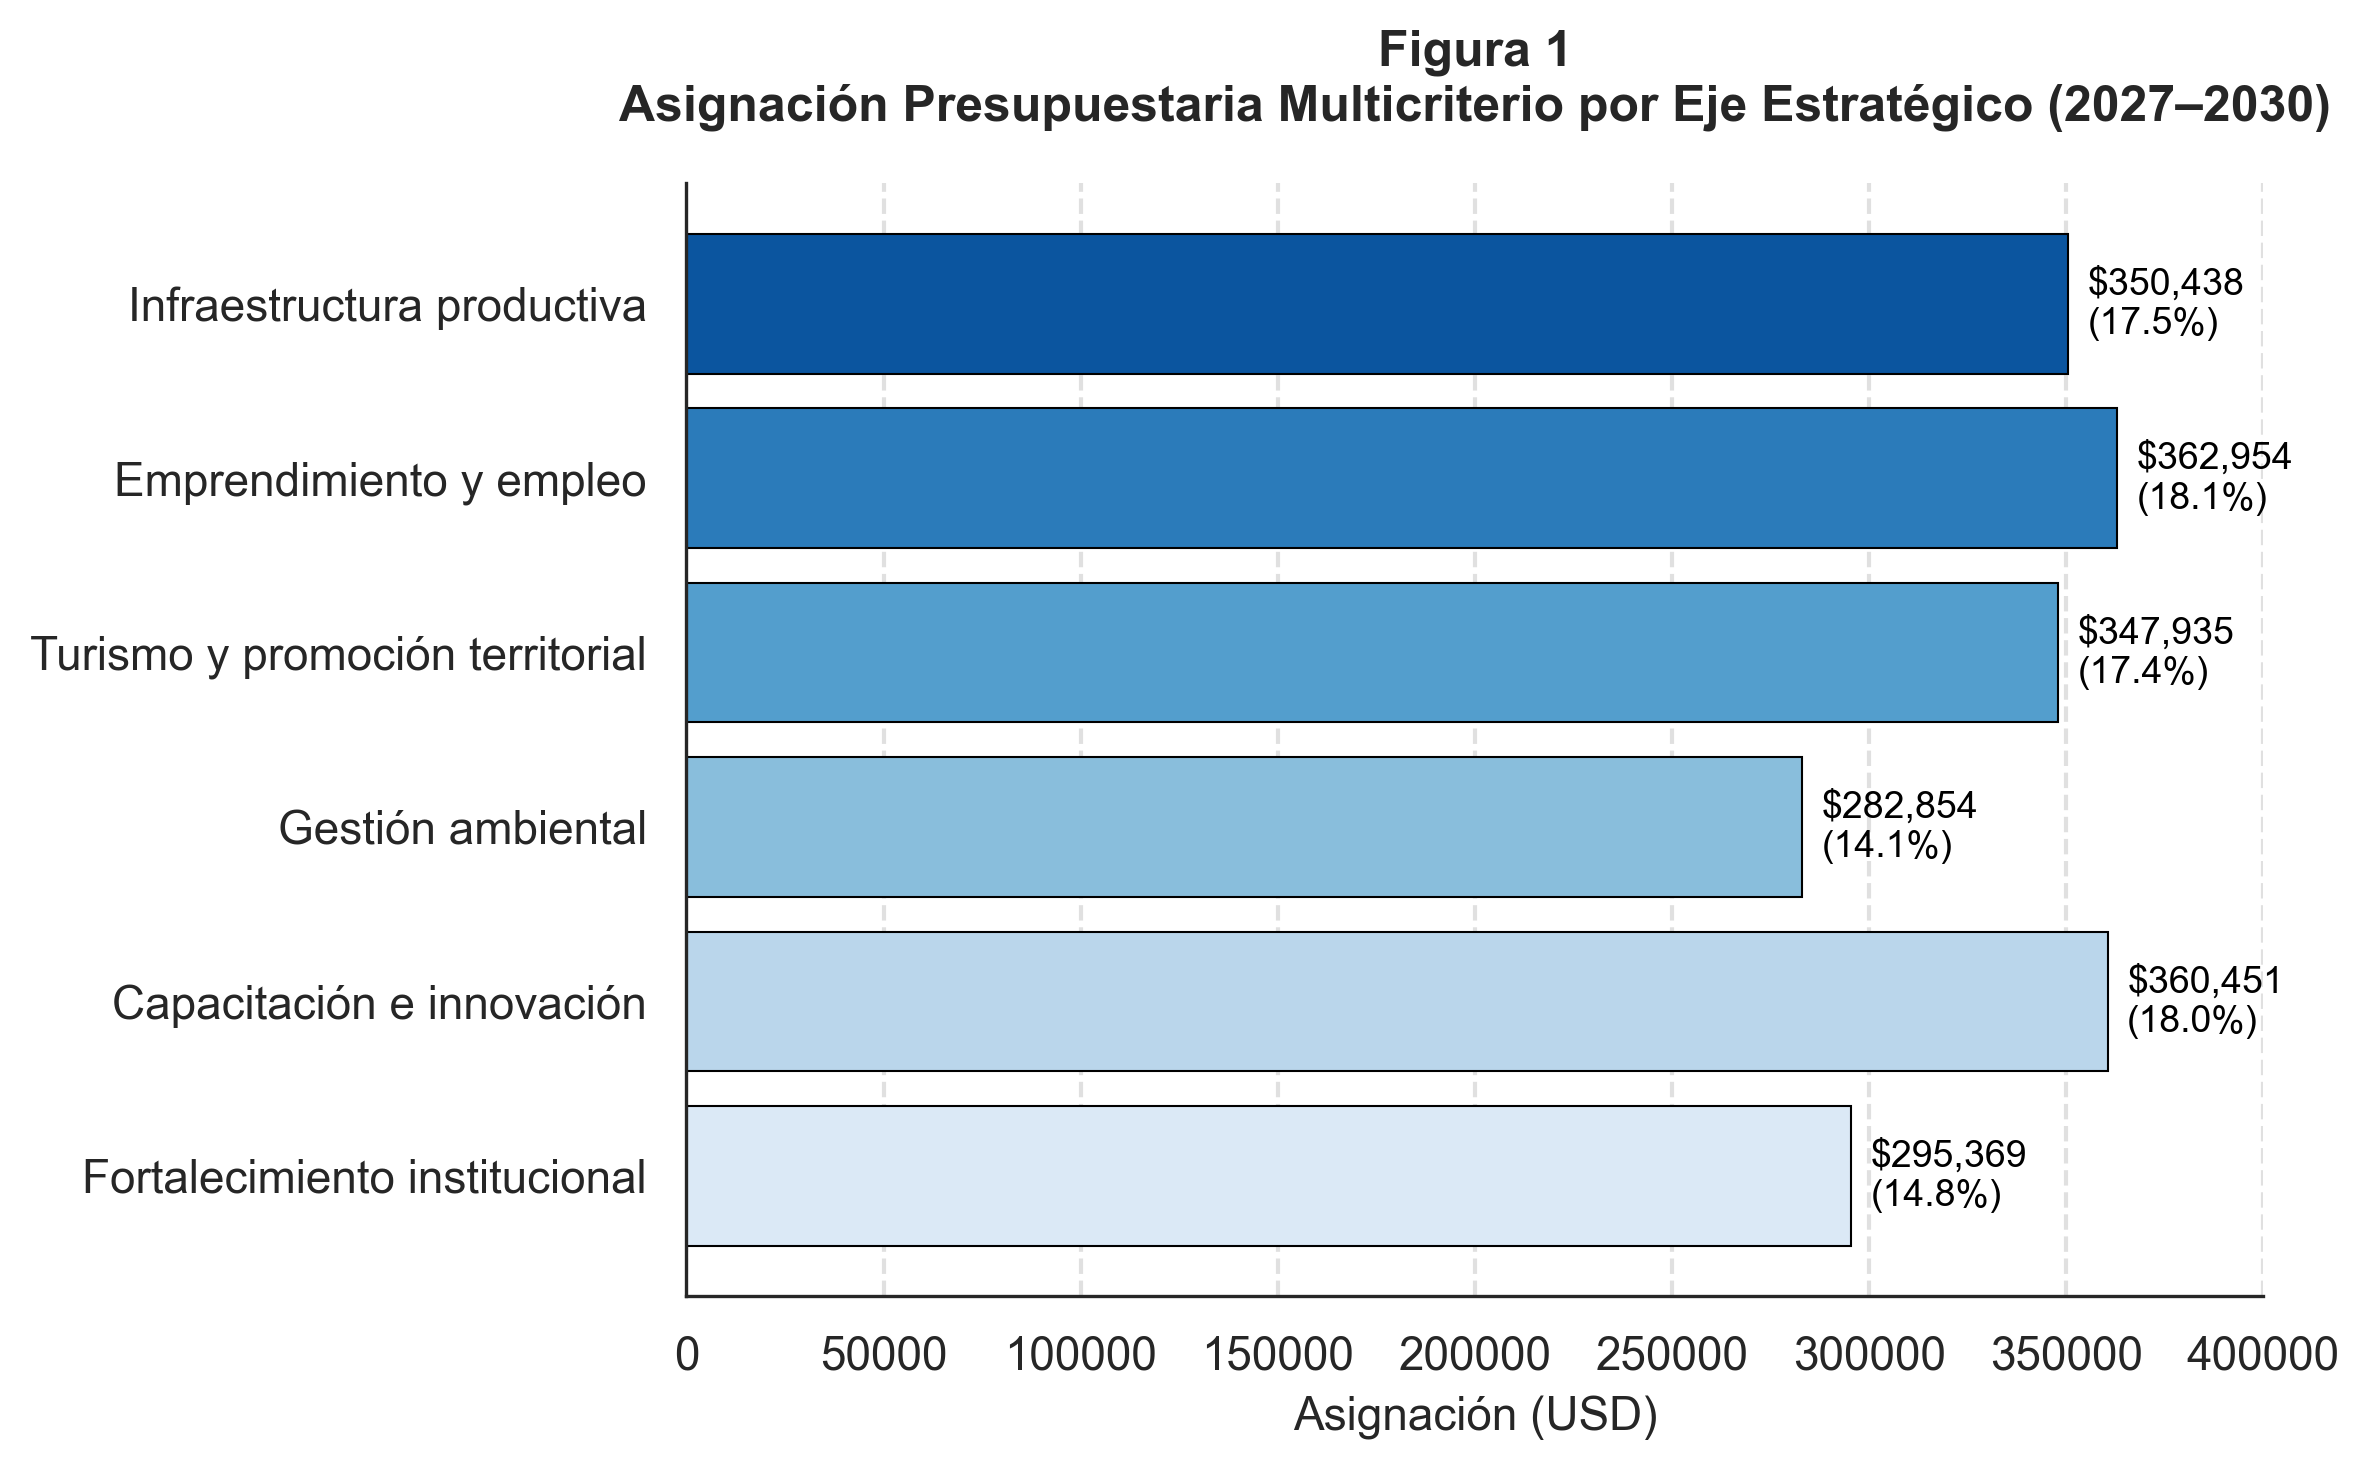

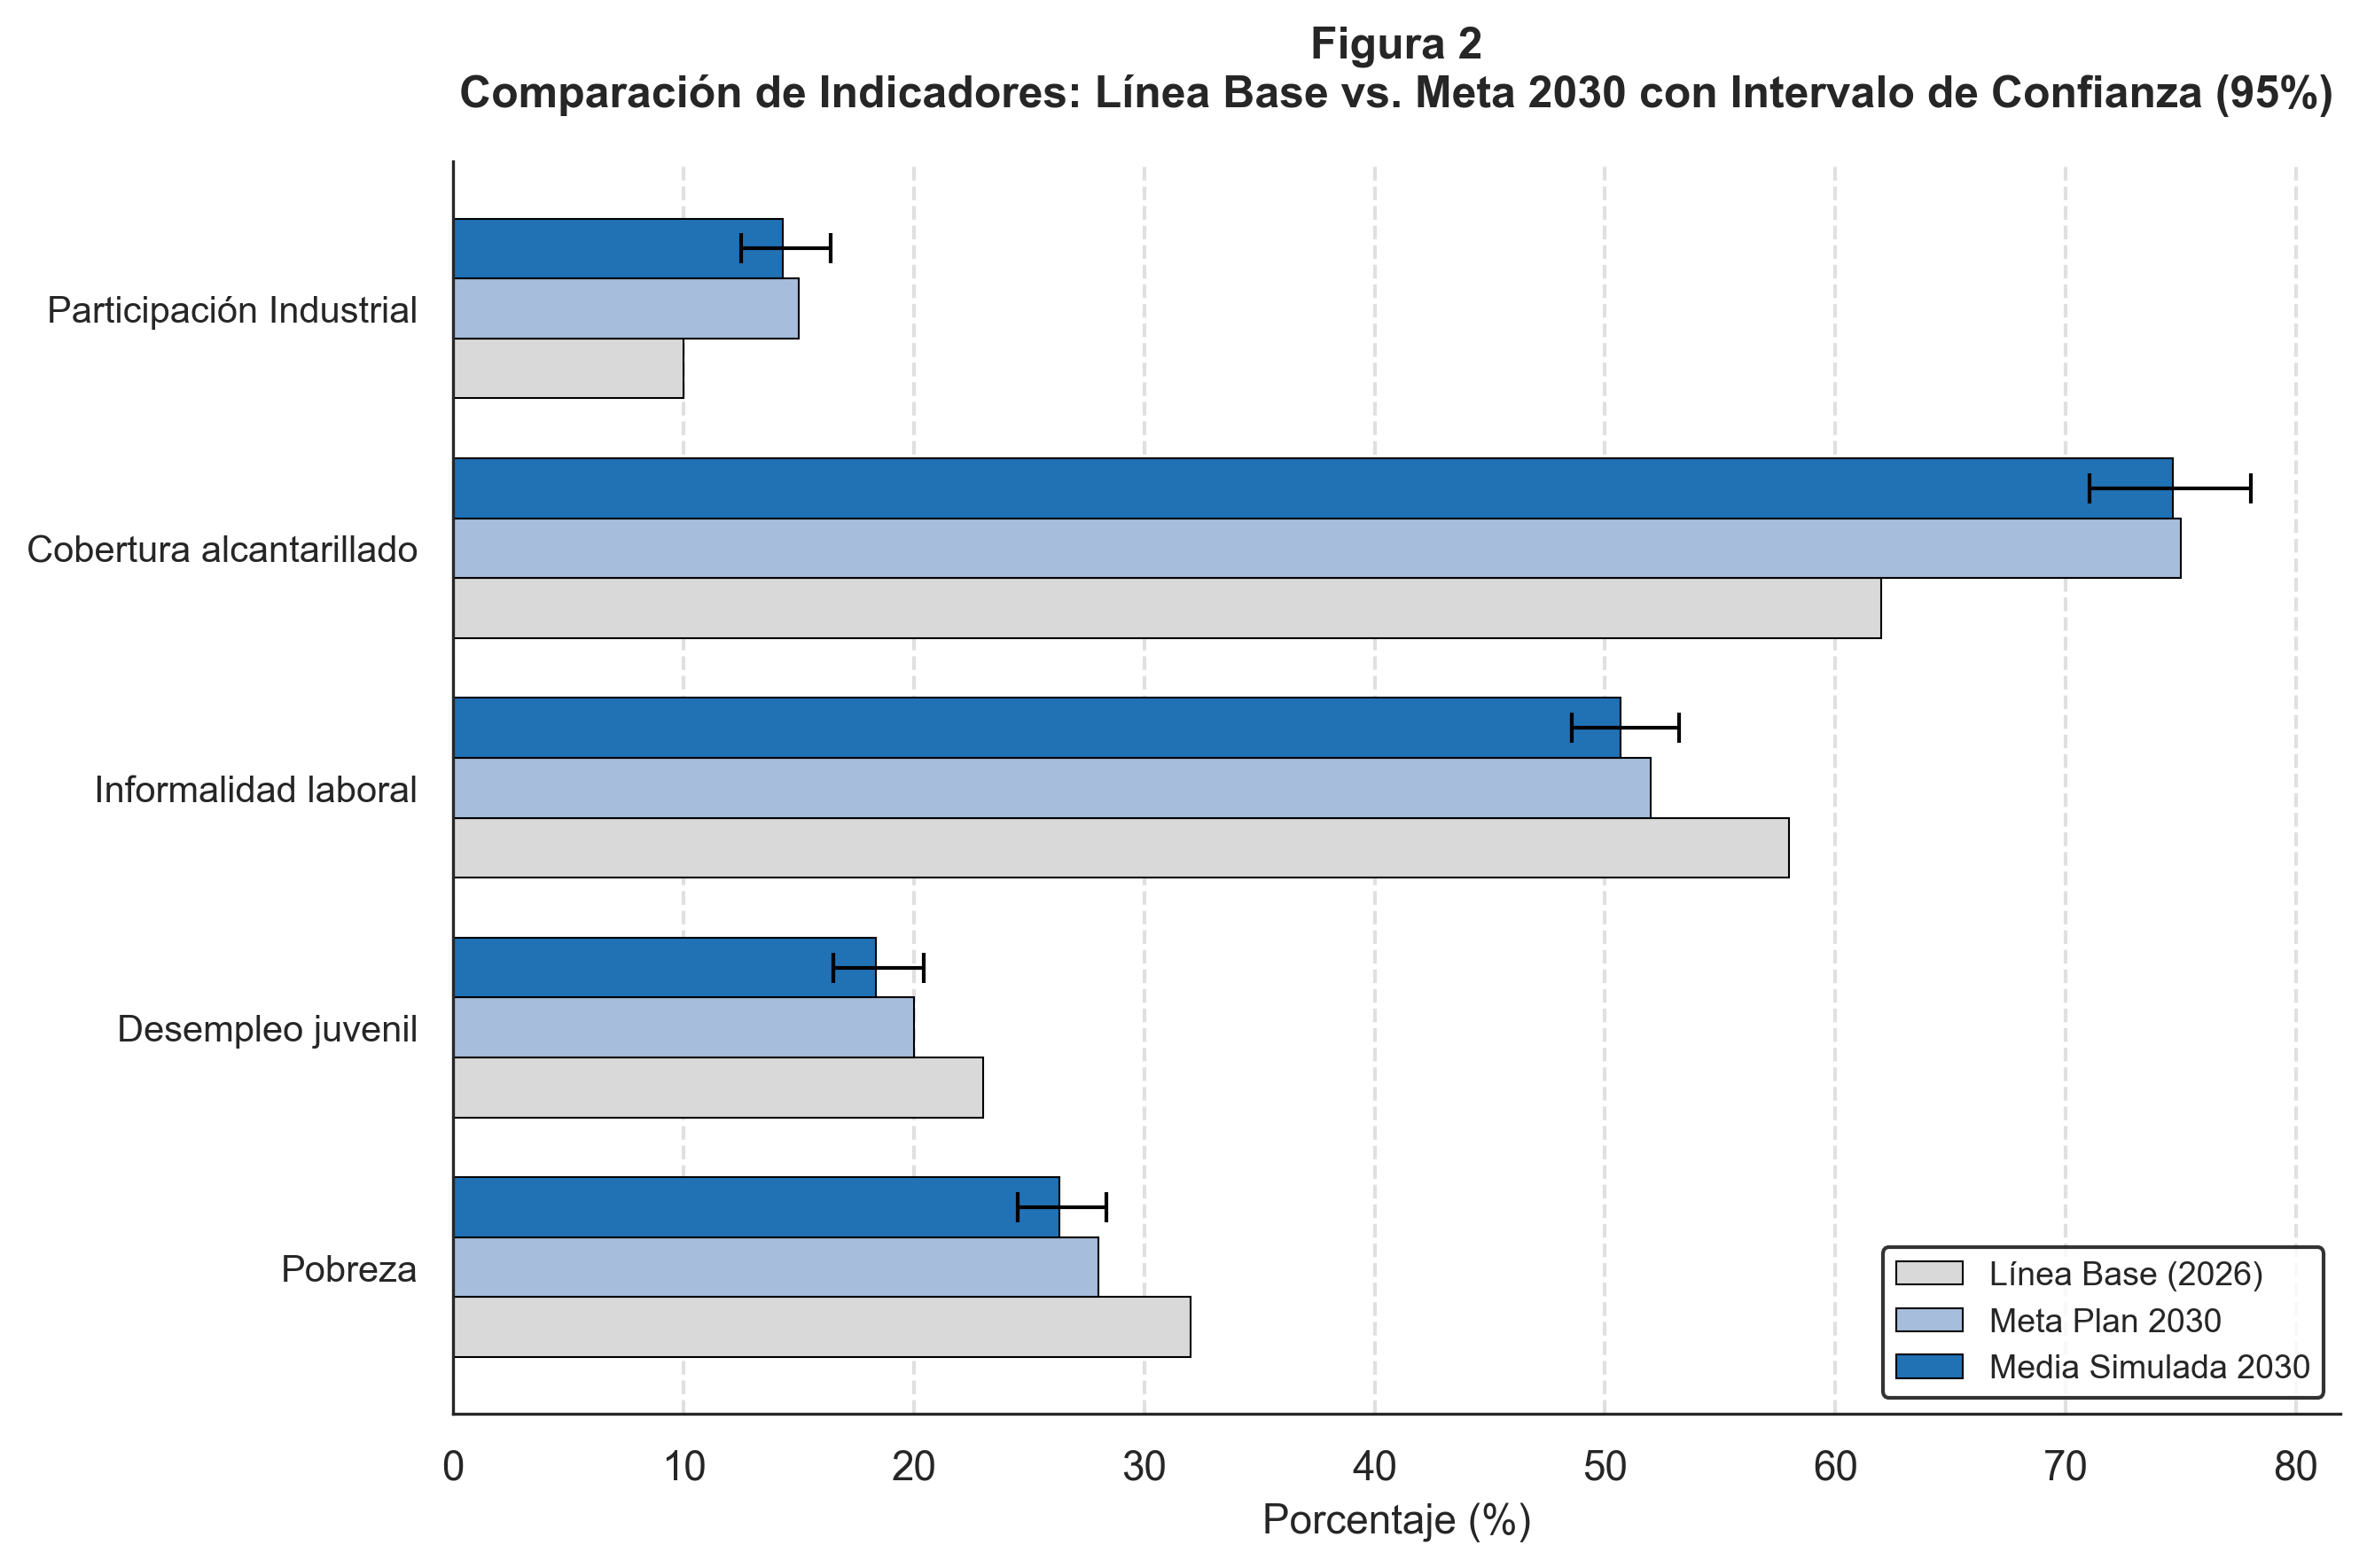


✅ VALIDACIÓN QA: Gráficos generados y guardados en alta resolución (300 DPI).
📁 Ubicación de las figuras: c:\Users\Oficina\Documents\Análisis de Datos Salomón\Tulcan_DesLocal_2027_2030\outputs\figuras


In [5]:
# ==============================================================================
# CELDA 5: MÓDULO 1.4 - Exportación de entregables visuales (APA 7, 300 DPI)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

# Reafirmar configuración APA 7
sns.set_theme(style="white", context="notebook", font="sans-serif")
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300
plt.rcParams['font.size'] = 10
plt.rcParams['axes.linewidth'] = 0.8

# -----------------------------------------------------------------------------
# FIGURA 1: Distribución presupuestaria por eje estratégico
# -----------------------------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(8, 5))

# Preparar datos de la Celda 3 (df_asignacion)
ejes_cortos = [e.split('. ')[1] if '. ' in e else e for e in df_asignacion["Eje estratégico"]]
valores_usd = df_asignacion["Asignación (USD)"]
colores = sns.color_palette("Blues_r", len(ejes_cortos))

# Gráfico de barras horizontales (invertido para que el mayor quede arriba)
bars = ax1.barh(ejes_cortos[::-1], valores_usd[::-1], color=colores[::-1], edgecolor='black', linewidth=0.5)

# Formato APA 7
ax1.set_title("Figura 1\nAsignación Presupuestaria Multicriterio por Eje Estratégico (2027–2030)", 
              fontsize=12, fontweight='bold', pad=15)
ax1.set_xlabel("Asignación (USD)", fontsize=11)
ax1.set_xlim(0, 400000)
ax1.grid(axis='x', linestyle='--', alpha=0.6)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

# Añadir etiquetas de valor en las barras
for bar in bars:
    width = bar.get_width()
    ax1.text(width + 5000, bar.get_y() + bar.get_height()/2, 
             f"${width:,.0f}\n({width/presupuesto*100:.1f}%)", 
             va='center', fontsize=9, color='black')

plt.tight_layout()
plt.savefig(OUTPUT_FIG / "Figura1_Asignacion_Presupuestaria.png", bbox_inches='tight')
plt.show()

# -----------------------------------------------------------------------------
# FIGURA 2: Comparación Línea Base vs. Meta 2030 con IC 95%
# -----------------------------------------------------------------------------
fig2, ax2 = plt.subplots(figsize=(9, 6))

# Preparar datos de la Celda 4
indicadores_plot = list(indicadores.keys())
y_pos = np.arange(len(indicadores_plot))

base_vals = [indicadores[ind]["base"] for ind in indicadores_plot]
meta_vals = [indicadores[ind]["meta"] for ind in indicadores_plot]
sim_media = [resultados_sim[ind]["Media"] for ind in indicadores_plot]
sim_ci_inf = [resultados_sim[ind]["IC_Inf"] for ind in indicadores_plot]
sim_ci_sup = [resultados_sim[ind]["IC_Sup"] for ind in indicadores_plot]

# Ancho de las barras
width = 0.25

# Barras agrupadas
ax2.barh(y_pos - width, base_vals, width, label='Línea Base (2026)', color='#d9d9d9', edgecolor='black', linewidth=0.5)
ax2.barh(y_pos, meta_vals, width, label='Meta Plan 2030', color='#a6bddb', edgecolor='black', linewidth=0.5)
ax2.barh(y_pos + width, sim_media, width, label='Media Simulada 2030', color='#2171b5', edgecolor='black', linewidth=0.5)

# Bandas de confianza (IC 95%) para la simulación (asimetría manejada por listas de errores)
xerr = [np.array(sim_media) - np.array(sim_ci_inf), np.array(sim_ci_sup) - np.array(sim_media)]
ax2.errorbar(sim_media, y_pos + width, xerr=xerr, fmt='none', color='black', capsize=4, linewidth=1)

# Formato APA 7
ax2.set_title("Figura 2\nComparación de Indicadores: Línea Base vs. Meta 2030 con Intervalo de Confianza (95%)", 
              fontsize=12, fontweight='bold', pad=15)
ax2.set_yticks(y_pos)
ax2.set_yticklabels([ind.replace(" (%)", "") for ind in indicadores_plot], fontsize=10)
ax2.set_xlabel("Porcentaje (%)", fontsize=11)
ax2.legend(loc='lower right', fontsize=9, frameon=True, edgecolor='black', facecolor='white')
ax2.grid(axis='x', linestyle='--', alpha=0.6)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(OUTPUT_FIG / "Figura2_Comparacion_Metas_2030.png", bbox_inches='tight')
plt.show()

print("\n✅ VALIDACIÓN QA: Gráficos generados y guardados en alta resolución (300 DPI).")
print(f"📁 Ubicación de las figuras: {OUTPUT_FIG}")

In [8]:
# ==============================================================================
# CELDA 6: MÓDULO 2.1 - Carga de ENEMDU 2025 (detección automática de separador)
# ==============================================================================
import pandas as pd
import numpy as np
from pathlib import Path
import csv

# 1. RUTA DEL ARCHIVO
PROJECT_ROOT = Path.cwd().parent
DATA_RAW = PROJECT_ROOT / "data" / "raw"

print("📂 6.1. UBICACIÓN DE ARCHIVOS")
print("-" * 60)

# Buscar el archivo
archivo_enemdu = None
for f in DATA_RAW.iterdir():
    if f.name.startswith("BDDenemdu_personas"):
        archivo_enemdu = f
        break

if archivo_enemdu is None:
    raise FileNotFoundError("❌ No se encontró BDDenemdu_personas_2025_anual en data/raw/")

print(f"  • Archivo: {archivo_enemdu.name}")
print(f"  • Tamaño: {archivo_enemdu.stat().st_size / 1024 / 1024:.2f} MB")

# 2. DETECTAR SEPARADOR AUTOMÁTICAMENTE
print("\n🔍 6.2. DETECCIÓN DE SEPARADOR")
print("-" * 60)

# Leer las primeras 5 líneas para inspeccionar
with open(archivo_enemdu, 'r', encoding='latin-1', errors='ignore') as f:
    primeras_lineas = [f.readline() for _ in range(5)]

print("  • Primeras 3 líneas del archivo (raw):")
for i, linea in enumerate(primeras_lineas[:3], 1):
    print(f"    Línea {i}: {linea[:100]}...")

# Detectar separador con csv.Sniffer
try:
    with open(archivo_enemdu, 'r', encoding='latin-1', errors='ignore') as f:
        muestra = f.read(8192)  # primeros 8KB
        separador = csv.Sniffer().sniff(muestra).delimiter
    print(f"\n  ✅ Separador detectado: '{separador}'")
except Exception as e:
    print(f"  ⚠️ No se pudo detectar automáticamente: {e}")
    separador = ';'  # fallback más común en INEC

# 3. CARGAR CSV CON SEPARADOR CORRECTO
print("\n📊 6.3. CARGA DE MICRODATOS")
print("-" * 60)

# Intentar con latin-1 (más común en INEC), luego utf-8
for encoding in ['latin-1', 'utf-8', 'cp1252']:
    try:
        df_enemdu = pd.read_csv(
            archivo_enemdu, 
            sep=separador, 
            encoding=encoding, 
            low_memory=False,
            on_bad_lines='warn'  # ignorar líneas mal formadas
        )
        print(f"  ✅ Cargado con: separador='{separador}', encoding='{encoding}'")
        break
    except Exception as e:
        print(f"  ⚠️ Falló con {encoding}: {e}")

print(f"  • Filas cargadas: {len(df_enemdu):,}")
print(f"  • Columnas: {df_enemdu.shape[1]}")
print(f"  • Primeras 10 columnas: {list(df_enemdu.columns[:10])}")

# 4. FILTRAR POR PROVINCIA DE CARCHI (código 4)
print("\n📍 6.4. FILTRADO POR PROVINCIA")
print("-" * 60)
print(f"  • Valores únicos de 'prov': {sorted(df_enemdu['prov'].dropna().unique())}")

df_carchi = df_enemdu[df_enemdu['prov'] == 4].copy()
print(f"  • Filas en Carchi (prov=4): {len(df_carchi):,}")

# 5. APLICAR FACTOR DE EXPANSIÓN
df_carchi['fexp'] = pd.to_numeric(df_carchi['fexp'], errors='coerce').fillna(1)
poblacion_expandida = df_carchi['fexp'].sum()
print(f"  • Población expandida (estimada Carchi): {poblacion_expandida:,.0f}")

# 6. CONSTRUCCIÓN DE VARIABLES
print("\n🔧 6.5. CONSTRUCCIÓN DE VARIABLES")
print("-" * 60)

# 6.1. POBREZA
df_carchi['pobreza'] = pd.to_numeric(df_carchi['pobreza'], errors='coerce').fillna(0).astype(int)
pobreza_pct = (df_carchi['pobreza'] * df_carchi['fexp']).sum() / df_carchi['fexp'].sum() * 100
print(f"  • Pobreza (Carchi 2025): {pobreza_pct:.2f}%")

# 6.2. POBREZA EXTREMA
df_carchi['epobreza'] = pd.to_numeric(df_carchi['epobreza'], errors='coerce').fillna(0).astype(int)
pobreza_ext_pct = (df_carchi['epobreza'] * df_carchi['fexp']).sum() / df_carchi['fexp'].sum() * 100
print(f"  • Pobreza extrema (Carchi 2025): {pobreza_ext_pct:.2f}%")

# 6.3. INFORMALIDAD (p05a/p05b: 1=Sí afiliado, 2=No afiliado)
df_carchi['p05a'] = pd.to_numeric(df_carchi['p05a'], errors='coerce').fillna(9).astype(int)
df_carchi['p05b'] = pd.to_numeric(df_carchi['p05b'], errors='coerce').fillna(9).astype(int)
df_carchi['empleo'] = pd.to_numeric(df_carchi['empleo'], errors='coerce').fillna(0).astype(int)

df_carchi['informal'] = np.where(
    (df_carchi['empleo'] == 1) & 
    ((df_carchi['p05a'] == 2) | (df_carchi['p05b'] == 2)),
    1, 0
)
empleados = df_carchi[df_carchi['empleo'] == 1]
if len(empleados) > 0:
    informalidad_pct = (empleados['informal'] * empleados['fexp']).sum() / empleados['fexp'].sum() * 100
else:
    informalidad_pct = 0
print(f"  • Informalidad laboral (Carchi 2025): {informalidad_pct:.2f}%")

# 6.4. ZONA RURAL (dominio: 1=Urbano, 2=Rural)
df_carchi['dominio'] = pd.to_numeric(df_carchi['dominio'], errors='coerce').fillna(1).astype(int)
df_carchi['zona_rural'] = np.where(df_carchi['dominio'] == 2, 1, 0)
rural_pct = (df_carchi['zona_rural'] * df_carchi['fexp']).sum() / df_carchi['fexp'].sum() * 100
print(f"  • Población rural (Carchi 2025): {rural_pct:.2f}%")

# 6.5. VARIABLES PARA MODELO
df_carchi['edad'] = pd.to_numeric(df_carchi['p03'], errors='coerce')
df_carchi['sexo'] = pd.to_numeric(df_carchi['p02'], errors='coerce').fillna(2).astype(int)
df_carchi['nivel_edu'] = pd.to_numeric(df_carchi['nnivins'], errors='coerce').fillna(0).astype(int)
df_carchi['ingreso_pc'] = pd.to_numeric(df_carchi['ingpc'], errors='coerce')

# 7. FILTRAR POBLACIÓN 15-64 AÑOS
print("\n🧹 6.6. LIMPIEZA PARA MODELO")
print("-" * 60)
df_modelo = df_carchi[(df_carchi['edad'] >= 15) & (df_carchi['edad'] <= 64)].copy()
print(f"  • Filas totales Carchi: {len(df_carchi):,}")
print(f"  • Filas 15-64 años: {len(df_modelo):,}")

vars_modelo = ['pobreza', 'edad', 'sexo', 'nivel_edu', 'ingreso_pc', 'zona_rural', 'fexp']
df_modelo = df_modelo.dropna(subset=vars_modelo)
print(f"  • Filas finales para modelo: {len(df_modelo):,}")

# 8. VALIDACIÓN QA
assert len(df_modelo) > 500, f"❌ Error QA: Muestra muy pequeña ({len(df_modelo)} obs)"
assert 0 <= pobreza_pct <= 100, "❌ Error QA: Pobreza fuera de rango"
assert 0 <= informalidad_pct <= 100, "❌ Error QA: Informalidad fuera de rango"

print(f"\n✅ VALIDACIÓN QA: Datos limpios y listos.")
print(f"  📊 Resumen Carchi 2025:")
print(f"     • Pobreza: {pobreza_pct:.2f}%")
print(f"     • Pobreza extrema: {pobreza_ext_pct:.2f}%")
print(f"     • Informalidad: {informalidad_pct:.2f}%")
print(f"     • Rural: {rural_pct:.2f}%")
print(f"     • Observaciones modelo: {len(df_modelo):,}")

# 9. GUARDAR
df_modelo.to_csv(DATA_RAW / "enemdu_carchi_limpio.csv", index=False, encoding='utf-8')
print(f"\n💾 Dataset limpio: {DATA_RAW / 'enemdu_carchi_limpio.csv'}")

📂 6.1. UBICACIÓN DE ARCHIVOS
------------------------------------------------------------
  • Archivo: BDDenemdu_personas_2025_anual.csv
  • Tamaño: 129.59 MB

🔍 6.2. DETECCIÓN DE SEPARADOR
------------------------------------------------------------
  • Primeras 3 líneas del archivo (raw):
    Línea 1: ï»¿area;ciudad;conglomerado;panelm;vivienda;hogar;p01;p02;p03;p04;p05a;p05b;p06;p07;p08;p09;p10a;p10...
    Línea 2: 1;10150;010150;067;01;1;01;2;64;1;1;10;4;2; ;1;10;2; ;1;50110101;6;2;10850;1;2;12;1;1;20;9; ; ; ; ; ...
    Línea 3: 1;10150;010150;067;01;1;01;2;65;1;1;10;4;2; ;2;10;2; ;1;50110101;6;2;10850;1;1; ; ; ;20;1; ;1;1;20;4...

  ✅ Separador detectado: ';'

📊 6.3. CARGA DE MICRODATOS
------------------------------------------------------------
  ✅ Cargado con: separador=';', encoding='latin-1'
  • Filas cargadas: 334,786
  • Columnas: 139
  • Primeras 10 columnas: ['ï»¿area', 'ciudad', 'conglomerado', 'panelm', 'vivienda', 'hogar', 'p01', 'p02', 'p03', 'p04']

📍 6.4. FILTRADO P

In [10]:
# ==============================================================================
# CELDA 7: MÓDULO 2.2 - Modelo Logit, Diagnóstico y Efectos Marginales (CORREGIDA)
# ==============================================================================
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import roc_auc_score, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

print("📊 7.1. PREPARACIÓN DE VARIABLES PARA EL MODELO LOGIT")
print("-" * 65)

# Usamos el df_modelo de la Celda 6
df_logit = df_modelo[['pobreza', 'edad', 'sexo', 'nivel_edu', 'zona_rural', 'fexp']].dropna().copy()

# Crear dummies correctos (INEC: sexo 1=Hombre, 2=Mujer)
df_logit['sexo_mujer'] = np.where(df_logit['sexo'] == 2, 1, 0)

# Verificar variación en zona_rural
if df_logit['zona_rural'].std() == 0:
    print("  ⚠️ zona_rural no tiene variación (todos son 0). Se excluye del modelo.")
    usar_zona_rural = False
else:
    usar_zona_rural = True

# Definir X e y (sin zona_rural si no tiene variación)
if usar_zona_rural:
    X = df_logit[['edad', 'sexo_mujer', 'nivel_edu', 'zona_rural']]
else:
    X = df_logit[['edad', 'sexo_mujer', 'nivel_edu']]

X = sm.add_constant(X)
y = df_logit['pobreza']
weights = df_logit['fexp']

print(f"  • Observaciones válidas para el modelo: {len(df_logit):,}")
print(f"  • Tasa de pobreza en la muestra: {(y * weights).sum() / weights.sum() * 100:.2f}%")
print(f"  • Variables predictoras: {list(X.columns[1:])}")

# -----------------------------------------------------------------------------
# 7.2. DIAGNÓSTICO DE MULTICOLINEALIDAD (VIF) - Solo variables predictoras
# -----------------------------------------------------------------------------
print("\n🔍 7.2. PRUEBA DE MULTICOLINEALIDAD (Factor de Inflación de la Varianza)")
print("-" * 65)
print("Nota: El VIF de la constante (const) se ignora por convención econométrica.")
print(f"{'Variable':<15} | {'VIF':>6}")
print("-" * 25)

# Calcular VIF solo para las variables predictoras (excluir 'const')
X_predictores = X.drop(columns=['const'])
vif_data = pd.DataFrame()
vif_data["Variable"] = X_predictores.columns
vif_data["VIF"] = [variance_inflation_factor(X_predictores.values, i) for i in range(len(X_predictores.columns))]

for _, row in vif_data.iterrows():
    vif_val = row["VIF"]
    estado = "✅" if vif_val < 5 else ("⚠️" if vif_val < 10 else "❌")
    print(f"{estado} {row['Variable']:<15} | {vif_val:>6.2f}")

# Assert QA: Ningún VIF de predictores debe ser mayor a 10
assert vif_data["VIF"].max() < 10, "❌ Error QA: Multicolinealidad severa detectada (VIF > 10)"
print("\n  ✅ Todos los VIF de predictores son < 10 (sin multicolinealidad severa)")

# -----------------------------------------------------------------------------
# 7.3. ESTIMACIÓN DEL MODELO LOGIT CON ERRORES ROBUSTOS (HC3)
# -----------------------------------------------------------------------------
print("\n📈 7.3. ESTIMACIÓN DEL MODELO LOGIT (Errores Estándar Robustos HC3)")
print("-" * 65)

logit_model = sm.Logit(y, X, freq_weights=weights)
result = logit_model.fit(cov_type='HC3', disp=0)

prueba_lr = result.llr
prueba_lr_pval = result.llr_pvalue
pseudo_r2 = result.prsquared

print(f"  • Pseudo R² de McFadden: {pseudo_r2:.4f}")
print(f"  • Test de Razón de Verosimilitud (LR): χ² = {prueba_lr:.2f}, p-value = {prueba_lr_pval:.4f}")
print(f"  • Significancia global del modelo: {'✅ SIGNIFICATIVO' if prueba_lr_pval < 0.05 else '❌ NO SIGNIFICATIVO'}")

# -----------------------------------------------------------------------------
# 7.4. EFECTOS MARGINALES PROMEDIO (AME)
# -----------------------------------------------------------------------------
print("\n💡 7.4. EFECTOS MARGINALES PROMEDIO (Average Marginal Effects - AME)")
print("-" * 65)
print("Interpretación: Cambio porcentual en la probabilidad de pobreza ante un cambio unitario en X.")
margeff = result.get_margeff()
print(margeff.summary())

# -----------------------------------------------------------------------------
# 7.5. ODDS RATIOS CON IC 95%
# -----------------------------------------------------------------------------
print("\n📊 7.5. ODDS RATIOS (OR) con IC 95%")
print("-" * 65)
params = result.params
conf = result.conf_int()
conf['Odds Ratio'] = params
conf.columns = ['IC 2.5%', 'IC 97.5%', 'Odds Ratio']
odds_ratios = np.exp(conf)
print(odds_ratios.round(3).to_string())

# -----------------------------------------------------------------------------
# 7.6. PODER PREDICTIVO: MATRIZ DE CONFUSIÓN Y CURVA ROC (AUC)
# -----------------------------------------------------------------------------
print("\n🎯 7.6. EVALUACIÓN PREDICTIVA (Umbral de clasificación = 0.5)")
print("-" * 65)

y_pred_prob = result.predict(X)
y_pred_class = (y_pred_prob >= 0.5).astype(int)

cm = confusion_matrix(y, y_pred_class, sample_weight=weights)
tn, fp, fn, tp = cm.ravel()
accuracy = (tp + tn) / (tp + tn + fp + fn)
sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0

auc = roc_auc_score(y, y_pred_prob, sample_weight=weights)

print(f"  • Exactitud (Accuracy): {accuracy:.2%}")
print(f"  • Sensibilidad (Tasa de acierto en pobres): {sensitivity:.2%}")
print(f"  • Área Bajo la Curva (AUC-ROC): {auc:.4f}")
print(f"  • Interpretación AUC: {'Excelente' if auc > 0.8 else 'Aceptable' if auc > 0.7 else 'Baja'}")

print("\n✅ VALIDACIÓN QA: Modelo Logit estimado, diagnosticado e interpretado correctamente.")

📊 7.1. PREPARACIÓN DE VARIABLES PARA EL MODELO LOGIT
-----------------------------------------------------------------
  ⚠️ zona_rural no tiene variación (todos son 0). Se excluye del modelo.
  • Observaciones válidas para el modelo: 2,251
  • Tasa de pobreza en la muestra: 18.39%
  • Variables predictoras: ['edad', 'sexo_mujer', 'nivel_edu']

🔍 7.2. PRUEBA DE MULTICOLINEALIDAD (Factor de Inflación de la Varianza)
-----------------------------------------------------------------
Nota: El VIF de la constante (const) se ignora por convención econométrica.
Variable        |    VIF
-------------------------
⚠️ edad            |   5.02
✅ sexo_mujer      |   2.08
⚠️ nivel_edu       |   5.30

  ✅ Todos los VIF de predictores son < 10 (sin multicolinealidad severa)

📈 7.3. ESTIMACIÓN DEL MODELO LOGIT (Errores Estándar Robustos HC3)
-----------------------------------------------------------------
  • Pseudo R² de McFadden: 0.0621
  • Test de Razón de Verosimilitud (LR): χ² = 133.45, p-value = 

In [11]:
# ==============================================================================
# CELDA 8: MÓDULO 2.3 - Exportación condensada de resultados econométricos
# ==============================================================================
import pandas as pd
from pathlib import Path

print("📂 8.1. PREPARACIÓN DE TABLAS PARA EXPORTACIÓN")
print("-" * 65)

# Asegurar que la carpeta de salida existe
OUTPUT_TAB.mkdir(parents=True, exist_ok=True)
ruta_exportacion = OUTPUT_TAB / "resumen_econometrico_modulo2.xlsx"

# 1. Tabla de Diagnóstico VIF (Solo predictores)
df_vif_export = vif_data.copy()
df_vif_export["VIF"] = df_vif_export["VIF"].round(2)

# 2. Tabla de Métricas Globales del Modelo
df_metricas = pd.DataFrame({
    "Métrica": [
        "Observaciones (n)",
        "Tasa de Pobreza Muestral (%)",
        "Pseudo R² de McFadden",
        "Test LR (Chi-cuadrado)",
        "p-value del Test LR",
        "Exactitud (Accuracy)",
        "Sensibilidad",
        "AUC-ROC"
    ],
    "Valor": [
        f"{len(df_logit):,}",
        f"{((y * weights).sum() / weights.sum() * 100):.2f}%",
        f"{result.prsquared:.4f}",
        f"{result.llr:.2f}",
        f"{result.llr_pvalue:.4f}",
        f"{accuracy:.2%}",
        f"{sensitivity:.2%}",
        f"{auc:.4f}"
    ]
})

# 3. Tabla de Efectos Marginales Promedio (AME)
# Extraemos los datos del resumen de margeff
ame_summary = margeff.summary()
# Convertimos el resumen de statsmodels a DataFrame limpiando el texto
ame_data = []
for row in ame_summary.tables[1].data[1:]: # Saltamos el encabezado
    ame_data.append({
        "Variable": row[0].strip(),
        "dy/dx (Efecto Marginal)": float(row[1]),
        "Error Estándar": float(row[2]),
        "z": float(row[3]),
        "p-value": float(row[4]),
        "IC 2.5%": float(row[5]),
        "IC 97.5%": float(row[6])
    })
df_ame = pd.DataFrame(ame_data)
df_ame = df_ame.round(4)

# 4. Tabla de Odds Ratios con IC 95%
df_or = odds_ratios.copy().round(3)
df_or = df_or.reset_index().rename(columns={"index": "Variable"})

print("✅ Tablas preparadas correctamente.")

# 5. EXPORTACIÓN A EXCEL CON MÚLTIPLES HOJAS
print(f"\n💾 8.2. EXPORTANDO A EXCEL: {ruta_exportacion.name}")
print("-" * 65)

try:
    with pd.ExcelWriter(ruta_exportacion, engine='openpyxl') as writer:
        df_metricas.to_excel(writer, sheet_name='01_Metricas_Globales', index=False)
        df_vif_export.to_excel(writer, sheet_name='02_Diagnostico_VIF', index=False)
        df_ame.to_excel(writer, sheet_name='03_Efectos_Marginales_AME', index=False)
        df_or.to_excel(writer, sheet_name='04_Odds_Ratios_IC95', index=False)
    
    print("✅ EXPORTACIÓN EXITOSA")
    print(f"  • Archivo guardado en: {ruta_exportacion}")
    print("  • Hojas incluidas:")
    print("    1. 01_Metricas_Globales (R², LR, AUC, Accuracy)")
    print("    2. 02_Diagnostico_VIF (Multicolinealidad)")
    print("    3. 03_Efectos_Marginales_AME (Interpretación económica principal)")
    print("    4. 04_Odds_Ratios_IC95 (Riesgo relativo)")
    
except Exception as e:
    print(f"❌ Error al exportar: {e}")
    print("💡 Alternativa: Exportando a CSVs individuales...")
    df_metricas.to_csv(OUTPUT_TAB / "metricas_globales.csv", index=False, sep=";")
    df_vif_export.to_csv(OUTPUT_TAB / "diagnostico_vif.csv", index=False, sep=";")
    df_ame.to_csv(OUTPUT_TAB / "efectos_marginales_ame.csv", index=False, sep=";")
    df_or.to_csv(OUTPUT_TAB / "odds_ratios.csv", index=False, sep=";")
    print(f"✅ CSVs guardados en: {OUTPUT_TAB}")

# 6. VALIDACIÓN QA
assert ruta_exportacion.exists() or (OUTPUT_TAB / "metricas_globales.csv").exists(), "❌ Error QA: No se generaron los archivos de salida"
print("\n✅ VALIDACIÓN QA: Archivos de resultados econométricos generados y verificados.")

📂 8.1. PREPARACIÓN DE TABLAS PARA EXPORTACIÓN
-----------------------------------------------------------------
✅ Tablas preparadas correctamente.

💾 8.2. EXPORTANDO A EXCEL: resumen_econometrico_modulo2.xlsx
-----------------------------------------------------------------
✅ EXPORTACIÓN EXITOSA
  • Archivo guardado en: c:\Users\Oficina\Documents\Análisis de Datos Salomón\Tulcan_DesLocal_2027_2030\outputs\tablas\resumen_econometrico_modulo2.xlsx
  • Hojas incluidas:
    1. 01_Metricas_Globales (R², LR, AUC, Accuracy)
    2. 02_Diagnostico_VIF (Multicolinealidad)
    3. 03_Efectos_Marginales_AME (Interpretación económica principal)
    4. 04_Odds_Ratios_IC95 (Riesgo relativo)

✅ VALIDACIÓN QA: Archivos de resultados econométricos generados y verificados.
